# Comparison of dataset v1 and v2
This was necessary cause we want to evaluate the MedRoBERTa model on unseen data, so making sure that the second version does not contain the same entries. 

In [ ]:
import re
import pandas as pd
from sklearn.model_selection import train_test_split

In [ ]:
df_v2 = pd.read_csv(
    r"C:\Users\guest5\Documents\jessa v2\export_bezoek_verslag_diagnose_v2.csv",
    delimiter="$",
)
print(df_v2.columns)
print(len(df_v2))
df_v1 = pd.read_csv(
    r"C:\Users\guest5\Documents\jessa v1\export_bezoek_verslag_diagnose.csv",
    delimiter="$",
)
print(df_v1.columns)
print(len(df_v1))


is_subset = (
    df_v1["volledig_verslag_report_content"]
    .isin(df_v2["volledig_verslag_report_content"])
    .all()
)
print(is_subset)

df_v1["in_v2"] = df_v1["volledig_verslag_report_content"].isin(
    df_v2["volledig_verslag_report_content"]
)
df_v1["in_v2"].value_counts()
df_v1_matched = df_v1[df_v1["in_v2"]]

df_v1_double_AF = df_v1_matched[df_v1_matched["diagnose_i48"] == 1]
print(len(df_v1_double_AF))

Index(['volledig_verslag_report_content', 'diagnose_i480', 'diagnose_i481',
       'diagnose_i482', 'diagnose_i483', 'diagnose_i484', 'diagnose_i489',
       'diagnose_i501', 'diagnose_i502', 'diagnose_i503', 'diagnose_i504',
       'diagnose_i508', 'diagnose_i509', 'diagnose_i69', 'diagnose_n171819',
       'diagnose_z8673'],
      dtype='object')
12692
Index(['volledig_verslag_report_content', 'diagnose_i48'], dtype='object')
12692
False
676


In [ ]:
df_v1_I48 = df_v1[df_v1["diagnose_i48"] == 1]
df_v2_I48 = df_v2[
    df_v2[
        [
            "diagnose_i480",
            "diagnose_i481",
            "diagnose_i482",
            "diagnose_i483",
            "diagnose_i484",
            "diagnose_i489",
        ]
    ]
    .isin([1])
    .any(axis=1)
]
print(len(df_v1_I48))
print(len(df_v2_I48))


is_subset = (
    df_v1_I48["volledig_verslag_report_content"]
    .isin(df_v2_I48["volledig_verslag_report_content"])
    .all()
)
print(is_subset)

1529
5185
False


In [ ]:
df_training_set = pd.read_csv(
    r"C:\Users\guest5\Documents\jessa v1\chads_vasc\datasets\processed_combined_dataset_with_labels_atleast_3_records_may.csv"
)
print(df_training_set.columns)

Index(['text', 'label'], dtype='object')


In [ ]:
in_training_set = df_v1_double_AF["volledig_verslag_report_content"].isin(
    df_training_set["text"]
)
print(in_training_set.value_counts())

volledig_verslag_report_content
False    676
Name: count, dtype: int64


We find that none of the AF entries that appear in both datasets, appear in the training set that is used for training the MedRoBERTa model. 

# Create a fixed test set for comparison of different methods

In [ ]:
df_total_set = pd.read_csv(
    r"C:\Users\guest5\Documents\jessa v1\chads_vasc\datasets\processed_combined_dataset_with_labels_atleast_3_records_may.csv"
)
print(df_total_set["label"].value_counts())

translate_labels = {
    0: 0,
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 5,
    6: 6,
    7: 7,
    8: 8,
    9: 9,
    10: 10,  # no_score
    13: 11,  # greater_than_2
}


df_total_set["translated_label"] = df_total_set["label"].map(translate_labels)

train_df_12, test_df_12 = train_test_split(
    df_total_set,
    test_size=0.2,
    random_state=42,
    stratify=df_total_set["translated_label"],
)


print(len(train_df_12))
print(len(test_df_12))

train_df_12.to_csv(
    r"..\code\Chadsvasc score extraction\datasets\train_df_12.csv", index=False
)
test_df_12.to_csv(
    r"..\code\Chadsvasc score extraction\datasets\test_df_12.csv", index=False
)


translate_labels = {
    0: 0,
    1: 1,
    2: 2,
    3: 3,
    4: 4,
    5: 5,
    6: 6,
    7: 7,
    10: 8,  # no_score
    13: 9,  # greater_than_2
}

# drop 8 and 9 cause they only appear 3 times
df = df_total_set[~df_total_set["label"].isin([8, 9])]

df["translated_label"] = df["label"].map(translate_labels)
train_df_10_2, test_df_10_2 = train_test_split(
    df, test_size=0.1, random_state=42, stratify=df["translated_label"]
)

print(len(train_df_10_2))
print(len(test_df_10_2))
print(test_df_10_2["label"].value_counts())

label
10    827
3     149
2     133
4     129
1      74
5      71
0      58
6      21
13     11
7      10
8       3
9       3
Name: count, dtype: int64
1191
298
1334
149
label
10    83
3     15
4     13
2     13
1      8
5      7
0      6
6      2
7      1
13     1
Name: count, dtype: int64


C:\Users\guest5\AppData\Local\Temp\ipykernel_1088\30985566.py:50: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["translated_label"] = df["label"].map(translate_labels)


In [ ]:
print(test_df_10["label"].value_counts())

label
10    166
3      30
2      27
4      26
1      15
5      14
0      11
6       4
13      2
7       2
Name: count, dtype: int64


# Create biggest test set possible from ground-truth data


In [ ]:
df_training_set = pd.read_csv(
    r"..\code\Chadsvasc score extraction\datasets\processed_combined_dataset_with_labels_atleast_3_records_may.csv"
)
print(df_training_set.columns)
df = df_training_set[~df_training_set["label"].isin([10, 13])]


print(len(df))

df.to_feather(
    r"..\code\Chadsvasc score extraction\datasets\largest_labeled_chads_set.feather"
)

Index(['text', 'label'], dtype='object')
651


# Create test set of 200 entries, with manual labelling


We first check the distribution of note lenghts. 

12516
Number of positive cases: 5115
count     5115.000000
mean     10889.532942
std       4964.322696
min        597.000000
25%       7365.000000
50%      10470.000000
75%      13901.500000
max      33992.000000
Name: text_length, dtype: float64


C:\Users\guest5\AppData\Local\Temp\ipykernel_1088\3261089230.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positive["text_length"] = df_positive["text"].astype(str).str.len()


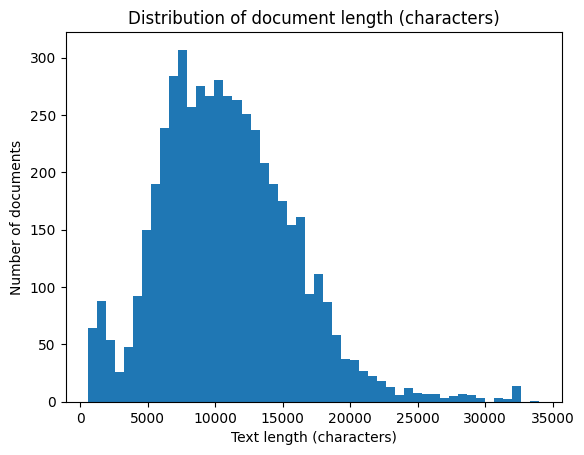

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

FILE = r"..\code\Chadsvasc score extraction\datasets\cleaned_notes_sections.feather"

df = pd.read_feather(FILE)
print(len(df))

af_columns = [
    "diagnose_i480",
    "diagnose_i481",
    "diagnose_i482",
    "diagnose_i483",
    "diagnose_i484",
    "diagnose_i489",
]
df_positive = df[df[af_columns].isin([1]).any(axis=1)]

print(f"Number of positive cases: {len(df_positive)}")

# Compute text length
df_positive["text_length"] = df_positive["text"].astype(str).str.len()

# Quick summary
print(df_positive["text_length"].describe())


# Plot distribution
plt.figure()
plt.hist(df_positive["text_length"], bins=50)
plt.xlabel("Text length (characters)")
plt.ylabel("Number of documents")
plt.title("Distribution of document length (characters)")
plt.show()

In [ ]:
df_sample = df_positive.sample(n=200, random_state=42)

df_sample["text_length"] = df_sample["text"].astype(str).str.len()

print("Full positive set:")
print(df_positive["text_length"].describe())

print("\nSample (n=200):")
print(df_sample["text_length"].describe())

Full positive set:
count     5115.000000
mean     10889.532942
std       4964.322696
min        597.000000
25%       7365.000000
50%      10470.000000
75%      13901.500000
max      33992.000000
Name: text_length, dtype: float64

Sample (n=200):
count      200.000000
mean     11056.430000
std       5058.461378
min        992.000000
25%       7413.250000
50%      10292.500000
75%      13774.750000
max      29572.000000
Name: text_length, dtype: float64


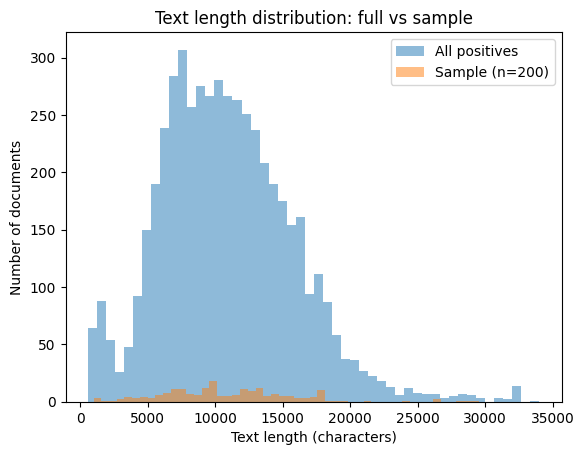

In [ ]:
plt.figure()
plt.hist(df_positive["text_length"], bins=50, alpha=0.5, label="All positives")
plt.hist(df_sample["text_length"], bins=50, alpha=0.5, label="Sample (n=200)")
plt.xlabel("Text length (characters)")
plt.ylabel("Number of documents")
plt.title("Text length distribution: full vs sample")
plt.legend()
plt.show()

In [ ]:
# Compute percentiles
p25 = df_positive["text_length"].quantile(0.25)
p75 = df_positive["text_length"].quantile(0.75)

print(f"25th percentile: {p25}")
print(f"75th percentile: {p75}")

# Count in your current sample
num_below_25 = (df_sample["text_length"] <= p25).sum()
num_between_25_75 = (
    (df_sample["text_length"] > p25) & (df_sample["text_length"] < p75)
).sum()
num_above_75 = (df_sample["text_length"] >= p75).sum()

print(f"Number of notes ≤25th percentile: {num_below_25}")
print(f"Number of notes between 25–75th percentile: {num_between_25_75}")
print(f"Number of notes ≥75th percentile: {num_above_75}")

25th percentile: 7365.0
75th percentile: 13901.5
Number of notes ≤25th percentile: 48
Number of notes between 25–75th percentile: 102
Number of notes ≥75th percentile: 50


In [12]:
print(df_sample.columns)

Index(['volledig_verslag_report_content', 'diagnose_i480', 'diagnose_i481',
       'diagnose_i482', 'diagnose_i483', 'diagnose_i484', 'diagnose_i489',
       'diagnose_i501', 'diagnose_i502', 'diagnose_i503', 'diagnose_i504',
       'diagnose_i508', 'diagnose_i509', 'diagnose_i69', 'diagnose_n171819',
       'diagnose_z8673', 'text', 'sections', 'text_length'],
      dtype='object')


In [ ]:
df_label = df_sample.copy()

df_label["Antecedenten"] = df_label["sections"].apply(
    lambda x: x.get("ANTECEDENTEN", "") if isinstance(x, dict) else ""
)
df_label["Risicofactoren"] = df_label["sections"].apply(
    lambda x: x.get("RISICOFACTOREN", "") if isinstance(x, dict) else ""
)
df_label["Besluit"] = df_label["sections"].apply(
    lambda x: x.get("BESLUIT", "") if isinstance(x, dict) else ""
)

df_label.drop(columns=["text", "sections"], inplace=True)


def extract_age(text):
    if not isinstance(text, str):
        return None
    match = re.search(
        r"(\d{2})-jarige", text
    )  # captures 2-digit number before '-jarige'
    if match:
        return int(match.group(1))
    return None


chadsvasc_columns = [
    "CHF",
    "HTN",
    "AGE_75",
    "DM",
    "STROKE",
    "VASCULAR",
    "AGE_65_74",
    "SEX_FEMALE",
]
df_label["age"] = df_label["Besluit"].apply(extract_age)

for col in chadsvasc_columns:
    df_label[col] = ""  # start empty for manual labeling

i50_columns = [
    "diagnose_i501",
    "diagnose_i502",
    "diagnose_i503",
    "diagnose_i504",
    "diagnose_i508",
    "diagnose_i509",
]
df_label["CHF"] = df_label[i50_columns].apply(
    lambda row: 1 if (row == 1).any() else "", axis=1
)


# Apply to BESLUIT section
df_label.loc[df_label["age"] >= 75, "AGE_75"] = 1
df_label.loc[(df_label["age"] >= 65) & (df_label["age"] < 75), "AGE_65_74"] = 1

df_label.to_excel("manual_sample_with_chadsvasc.xlsx")

# df_label.to_csv("sample.csv")

# Create validation set (100 entries)

In [ ]:
# Creation of validation set for threshold tuning
# df_subset = df.sort_index()
# df_sample = df_subset.sample(n=100, random_state=21)
# df_train = df_subset.drop(df_sample.index)

# print("Training set size:", len(df_train))

# import re

# df_label = df_sample.copy()
# df_label['Anamnese'] = df_label['sections'].apply(lambda x: x.get('ANAMNESE', '') if isinstance(x, dict) else '')
# df_label['Antecedenten'] = df_label['sections'].apply(lambda x: x.get('ANTECEDENTEN', '') if isinstance(x, dict) else '')
# df_label['Risicofactoren'] = df_label['sections'].apply(lambda x: x.get('RISICOFACTOREN', '') if isinstance(x, dict) else '')
# df_label['Besluit'] = df_label['sections'].apply(lambda x: x.get('BESLUIT', '') if isinstance(x, dict) else '')
# df_label['Medicatie'] = df_label['sections'].apply(lambda x: x.get('MEDICATIE', '') if isinstance(x, dict) else '')

# df_label.drop(columns=['sections', 'uppercase_titles', 'text_length', 'num_titles'], inplace=True)

# def extract_age(text):
#     if not isinstance(text, str):
#         return None
#     match = re.search(r'(\d{2})-jarige', text)  # captures 2-digit number before '-jarige'
#     if match:
#         return int(match.group(1))
#     return None

# def extract_sex(text):
#     if not isinstance(text, str):
#         return None
#     if re.search(r'patiënte', text):
#         return "F"
#     return "M"

# chadsvasc_columns = [
#     'CHF',
#     'HTN',
#     'AGE_75',
#     'DM',
#     'STROKE',
#     'VASCULAR',
#     'AGE_65_74',
#     'SEX_FEMALE'
# ]
# df_label['age'] = df_label['Besluit'].apply(extract_age)
# df_label['sex'] = df_label['Besluit'].apply(extract_sex)

# for col in chadsvasc_columns:
#     df_label[col] = np.nan

# i50_columns = [ 'diagnose_i501', 'diagnose_i502', 'diagnose_i503', 'diagnose_i504',
#                 'diagnose_i508', 'diagnose_i509']
# df_label['CHF'] = df_label[i50_columns].apply(lambda row: 1 if (row == 1).any() else '', axis=1)

# i10_15_columns = ['diagnose_i10','diagnose_i11', 'diagnose_i12', 'diagnose_i13', 'diagnose_i15']
# df_label['HTN'] = df_label[i10_15_columns].apply(lambda row: 1 if (row == 1).any() else '', axis=1)

# e10_14_columns = ['diagnose_e10', 'diagnose_e11', 'diagnose_e12', 'diagnose_e13','diagnose_e14']
# df_label['DM'] = df_label[e10_14_columns].apply(lambda row: 1 if (row == 1).any() else '', axis=1)

# stroke_columns = ['diagnose_i69', 'diagnose_z8673']
# df_label['STROKE'] = df_label[stroke_columns].apply(lambda row: 1 if (row == 1).any() else '', axis=1)

# df_label.loc[df_label['age'] >= 75, 'AGE_75'] = 1
# df_label.loc[(df_label['age'] >= 65) & (df_label['age'] < 75), 'AGE_65_74'] = 1

# df_label.loc[df_label['sex'] == "F", 'SEX_FEMALE'] = 1
# df_label.drop(columns=["sex"], inplace=True)


# df_label.to_excel("manual_sample_thresholds.xlsx")
# from openpyxl import load_workbook
# from openpyxl.styles import Font

# # Load workbook
# wb = load_workbook("manual_sample_thresholds.xlsx")
# ws = wb.active

# # Define uniform font
# uniform_font = Font(
#     name="Calibri",  # change if you want (e.g. Arial)
#     size=11
# )

# # Apply font to ALL cells
# for row in ws.iter_rows():
#     for cell in row:
#         cell.font = uniform_font

# # Save workbook
# wb.save("manual_sample_thresholds.xlsx")

# df = df_train.copy()
# df.to_feather("datasets/new_training_set.feather")
ABSTAIN = -1
ABSENT = 0
PRESENT = 1

lfs_for_component = {}

FAM_KEYWORDS = [
    "familie",
    "familiale",
    "erfelijk",
    "erfelijkheid",
    "moeder",
    "vader",
    "broer",
    "zus",
]

## Using unstructured information, note: medication is treated as a separate component ##
relevant_sections = [
    "BESLUIT",
    "ANTECEDENTEN",
    "RISICOFACTOREN",
    "ANAMNESE",
]

# def make_positive_lf(pos_list):
#     """
#     Factory function to create a positive LF for any list of positive concepts.

#     Parameters:
#         pos_list (list): List of regex patterns for the positive concepts.
#         neg_keywords (list): List of negation keywords.
#         window (int): Number of words around the concept to look for negation.

#     Returns:
#         labeling_function: A Snorkel LF that returns PRESENT if any positive concept is found.
#     """
#     @labeling_function(name="positive_lf")
#     def lf(x):
#         text = ' '.join(str(x['sections'].get(sec, '')).lower() for sec in relevant_sections)
#         text = x['text'].lower() if pd.notnull(x['text']) else ''
#         if any(re.search(p, text) for p in pos_list):
#             return PRESENT
#         return ABSTAIN

#     return lf


# Negation-aware positive LF
def make_positive_lf(
    pos_list,
    pre_keywords=["geen", "niet", "zonder"],
    post_keywords=["negatief", "afwezig"],
):
    @labeling_function(name="positive_lf")
    def lf(x):
        text = str(x.get("text", "")).lower()
        if not text:
            return ABSTAIN

        lines = text.splitlines()
        for line in lines:
            for pattern in pos_list:
                match = re.search(pattern, line)
                if match:
                    start, end = match.span()
                    prefix = line[:start]
                    suffix = line[end:]

                    # If it's negated on this line, this LF should ABSTAIN
                    # (letting the negation_lf handle it)
                    if any(neg in prefix for neg in pre_keywords):
                        continue
                    if any(neg in suffix for neg in post_keywords):
                        continue

                    # If we found the match and NO negation keywords on this line
                    return PRESENT

        return ABSTAIN

    return lf


def make_negation_lf(
    pos_list,
    pre_keywords=["geen", "niet", "zonder"],
    post_keywords=["negatief", "afwezig", "uitgesloten"],
):
    @labeling_function(name="negation_lf")
    def lf(x):
        text = str(x.get("text", "")).lower()
        if not text:
            return ABSTAIN

        lines = text.splitlines()

        for line in lines:
            for concept_pattern in pos_list:
                match = re.search(concept_pattern, line)
                if match:
                    start_char, end_char = match.span()

                    # 1. Check BEFORE the concept (Prefix)
                    prefix_text = line[:start_char]
                    if any(neg in prefix_text for neg in pre_keywords):
                        return ABSENT

                    # 2. Check AFTER the concept (Suffix)
                    suffix_text = line[end_char:]
                    if any(neg in suffix_text for neg in post_keywords):
                        return ABSENT

        return ABSTAIN

    return lf


def make_family_lf(pos_list):

    @labeling_function(name="family_lf")
    def lf(x):
        text = x["text"].lower() if pd.notnull(x["text"]) else ""
        lines = text.split("\n")

        for line in lines:
            for concept_pattern in pos_list:
                for match in re.finditer(concept_pattern, line):

                    if any(fam in line for fam in FAM_KEYWORDS):
                        return ABSENT

        return ABSTAIN

    return lf